In [2]:
import generate_clouds as gc
import aster_subroutine as ast
import xarray as xr
import scipy.stats as st
import numpy as np
import matplotlib.pyplot as plt
import os
import collections
from scipy.optimize import curve_fit

In [3]:
def cloud_mean_tau(cloud):
    return np.mean(cloud.optical_depth.data[np.where(cloud.optical_depth.data > 0)])

def cloud_std_cth(cloud):
    return np.nanstd(cloud.cth.data)

def calc_lambda(cloud, maxD=7, bins=np.arange(0,7,0.1)):
    totalpixels = np.count_nonzero(~np.isnan(cloud.mask.data))
    outmask, totalflag, number = ast.flag_each_cloud(cloud.mask.data)
    # onns, nnpair = ast.nns(outmask,totalflag)
    # edge = ast.perimeter(outmask,totalflag)
    c = collections.Counter(outmask.flatten())
    del c[0]
    cloudypixels = sum(c.values())
    cloudfraction = cloudypixels/totalpixels
    cloud['outmask'] = (['x','y'], outmask)
    cloud = cloud.assign_coords(cloud_element=('cloud_element', list(c.keys())))
    cloud['numpixels'] = (['cloud_element'], list(c.values()))
    cloud['cloud_area'] = cloud.numpixels * cloud.delx * cloud.dely
    cloud['equiv_diameter'] = (4 * cloud.cloud_area / np.pi)**0.5

    tmpcloud = cloud.isel(cloud_element=np.where(cloud.equiv_diameter.data < maxD)[0]).copy(deep=True)
    bins_list = list(bins)
    weights = np.ones_like(tmpcloud.equiv_diameter.data)/tmpcloud.sizes['cloud_element']
    n, bins = np.histogram(tmpcloud.equiv_diameter.data, bins=bins_list, weights=weights)
    bin_center = (bins[1:] + bins[:-1])*0.5
    pars2, cov2 = curve_fit(f=line_law, xdata=np.log(bin_center[n!=0]), ydata=np.log(n[n!=0]))
    cloud.attrs['parm0'] = pars2[0]
    cloud.attrs['parm1'] = pars2[1]
    cloud.attrs['cf_calc'] = cloudfraction
    return cloud

def set_properties(cloud):
    cloud['optical_depth'] = cloud.density.integrate('z')
    cloud['cth'] = cloud.z.where(cloud.density > 0).max('z')
    cloud['cbh'] = cloud.z.where(cloud.density > 0).min('z')
    cloud['thickness'] = cloud.cth - cloud.cbh
    cloud['mask'] = cloud.cth.notnull()
    rho_l = 1000 # kg/m^3
    cloud['lwc'] = (2/3) * cloud.density * 1e-3 * rho_l * cloud.reff * 1e-6 # kg/m^3
    cloud['lwp'] = cloud.lwc.integrate('z') * 1e3 * 1e3 # g/m^2
    cloud['nan_lwc'] = cloud.lwc.copy(deep=True)
    cloud.nan_lwc.data[cloud.lwc.data == 0] = np.nan
    cloud['lwc_h_std'] = cloud.nan_lwc.std(['x'], skipna=True)
    cloud['lwc_fc'] = cloud.lwc_h_std / cloud.nan_lwc.mean(['x'], skipna=True)
    if(cloud.cf < 0.99):
        cloud = calc_lambda(cloud)
    return cloud

def line_law(x, a, b):
    return (a - b*(x))

def calc_relstd(cf):
    percentile = st.norm.ppf(1.0-cf)
    r = st.truncnorm.rvs(a=percentile, b=np.inf, size=100000)
    b = (r-r.min())
    b /= b.mean()
    b *= 0.4/b.mean()
    return b.std()/b.mean()


In [4]:
# def boutle_helper(cf, L):
#     return (L*cf)**(1/3) * ((0.06*L*cf)**1.5 + 1)**-0.17
# def boutle_param(cf, L):
#     if(cf == 1):
#         return 0.11 * boutle_helper(cf, L)
#     else:
#         return (0.45 - 0.25*cf) * boutle_helper(cf, L)
    
# cf = np.linspace(0, 1, 500)
# bp = np.zeros(len(cf))
# L = 150 # km
# for i, C in enumerate(cf):
#     bp[i] = boutle_param(C, L)
# plt.plot(cf, bp)
# plt.xlabel('cloud fraction')
# plt.ylabel('Fc')

In [5]:
def plotCloud(cloud, savebase=None, filename=None):
    f, axs = plt.subplots(2, 5, figsize=(27, 8))
    cloud.cth.plot(ax=axs[0,0])
    axs[0,0].set_title('Cloud Top Height [km]')

    cloud.optical_depth.plot(ax=axs[0,1])
    axs[0,1].set_title('Cloud Optical Depth')

    cloud['mask'].plot(cmap='gray', ax=axs[0,2])

    cloud.lwp.plot(ax=axs[0,3])
    axs[0,3].set_title('LWP [g/m^2]')

    cloud.lwc_fc.plot(x='y', ax=axs[0,4])

    h = axs[1,0].hist(cloud.cth.data[np.bitwise_not(np.isnan(cloud.cth.data))], bins=np.linspace(np.min(cloud.z.data), np.max(cloud.z.data), 40))
    cth_mean = np.nanmean(cloud.cth.data)
    cth_std = cloud_std_cth(cloud)
    axs[1,0].vlines(cth_mean, 0, np.max(h[0]), 'k', label='cloud-mean cth: {:.3f} km'.format(cth_mean))
    axs[1,0].vlines([cth_mean-cth_std, cth_mean+cth_std], 0, np.max(h[0]), 'k', linestyles='dashed', label='std cth: {:.3f} km\nrelstd: {:.3f}'.format(cth_std, cth_std/cloud.thickness.mean().data))
    axs[1,0].legend()
    axs[1,0].set_xlabel('Cloud Top Height [km]')

    h = axs[1,1].hist(cloud.optical_depth.data[cloud.optical_depth.data > 0], bins=np.logspace(-2, 3, 40))
    mean_tau = cloud_mean_tau(cloud)
    axs[1,1].vlines(mean_tau, 0, np.max(h[0]), 'k', label='cloud-mean tau: {:.2f}'.format(mean_tau))
    axs[1,1].legend()
    # axs[1,1].text(0.8, 0.8, 'mean tau: {:.2f}'.format(mean_tau))
    axs[1,1].set_xscale('log')
    axs[1,1].set_xlabel('Optical depth')

    txt = '\n'.join([f'{key:<15s} {value:<n}' for key, value in cloud.attrs.items()])
    axs[1,2].text(0.0, 0.0, txt, fontsize='medium', fontfamily='monospace')
    axs[1,2].set_axis_off()

    h = axs[1,3].hist(cloud.lwp.data[cloud.lwp.data > 0], bins=np.logspace(-1, 3, 40))
    mean_lwp = np.mean(cloud.lwp.data[np.where(cloud.lwp.data > 0)])
    axs[1,3].vlines(mean_lwp, 0, np.max(h[0]), 'k', label='cloud-mean lwp: {:.2f} g/m^2'.format(mean_lwp))
    axs[1,3].legend()
    # axs[1,1].text(0.8, 0.8, 'mean tau: {:.2f}'.format(mean_tau))
    axs[1,3].set_xscale('log')
    axs[1,3].set_xlabel('LWP [g/m^2]')

    if(cloud.cf < 0.99):
        tmpcloud = cloud.isel(cloud_element=np.where(cloud.equiv_diameter.data < 7)[0]).copy(deep=True)
        bins_list = list(np.arange(0,7,0.1))
        weights = np.ones_like(tmpcloud.equiv_diameter.data)/tmpcloud.sizes['cloud_element']
        n, bins, patches = axs[1,4].hist(x=tmpcloud.equiv_diameter.data, bins=bins_list, histtype=u'step', weights=weights, label='Observations')
        # n[n==0]=1
        bin_center = (bins[1:] + bins[:-1])*0.5
        # pars2, cov2 = curve_fit(f=line_law, xdata=np.log(bin_center), ydata=np.log(n))
        axs[1,4].plot(bin_center, np.exp(line_law(np.array(np.log(bin_center)), *(tmpcloud.parm0,tmpcloud.parm1))), linestyle='--', linewidth=1.5, color='black', label='Line Fit ($\lambda$=%.2f)' % tmpcloud.parm1)
        axs[1,4].legend()
        axs[1,4].set_xscale('log')
        axs[1,4].set_yscale('log')
        axs[1,4].set_xlabel('Cloud Equivalent Diameter (km)')
        axs[1,4].set_ylabel('Normalized Frequency')
        axs[1,4].grid()
        axs[1,4].set_xlim(1,10)
    else:
        axs[1,4].set_axis_off()

    if(savebase != None):
        figsavebase = savebase + '/figures'
        densavebase = savebase + '/density'
        os.makedirs(figsavebase, exist_ok=True)
        os.makedirs(densavebase, exist_ok=True)

        figsavename = figsavebase + '/' + filename + '00.png'
        densavename = densavebase + '/' + filename + '00.nc'

        i = 0
        while(os.path.isfile(figsavename) or os.path.isfile(densavename)):
            figsavename = '{}/{}{:02d}.png'.format(figsavebase, filename, i)
            densavename = '{}/{}{:02d}.nc'.format(densavebase, filename, i)
            i += 1

        f.savefig(figsavename)
        cloud.to_netcdf(densavename)


# Trade Cumulus

## Stochastic

/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:48: RuntimeWarning: invalid value encountered in power
  means = (big_z-cbase)**(tau_power - 1.0)
/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:67: RuntimeWarning: Mean of empty slice
  reff = np.sqrt(1e3*np.nanmean(means, axis=(0,1))/(2*np.pi*k*N0))[None,None]*np.ones(ext.shape)
/data/keeling/a/johntl3/miniconda3/envs/synthetic/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


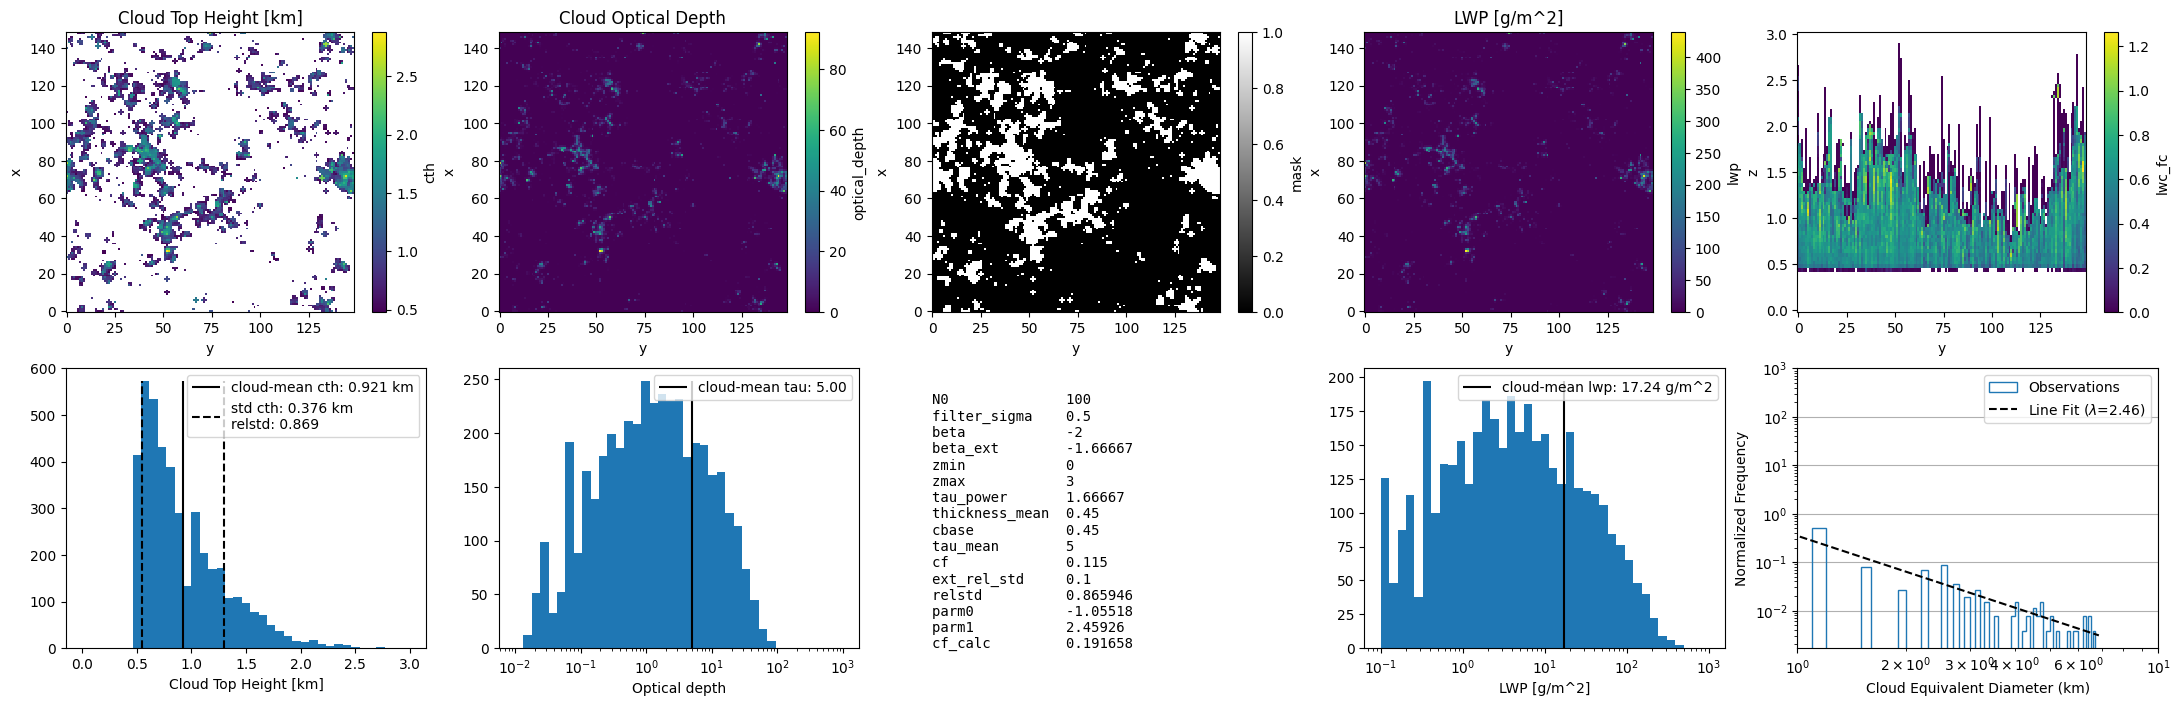

In [9]:
nx = 149
ny = 149
dx = 1.0
dy = 1.0
dz = 0.040
zmin = 0.0
zmax = 3.0
beta = -2
beta_ext = -5.0/3.0
cf = 0.115
ext_rel_std = 0.1
tau_mean = 5
relstd = calc_relstd(cf)
thickness_mean = 0.45
tau_power=5.0/3.0
veff = 0.07
N0 = 100.0
cbase=0.450
filter_sigma=0.5
cloud = gc.generate_cloud(nx, ny, dx, dy, dz, zmin, zmax, beta, beta_ext, cf, ext_rel_std,
                        tau_mean, relstd, thickness_mean, tau_power, veff, N0, cbase, filter_sigma)
cloud = set_properties(cloud)

outpath = '/data/keeling/a/johntl3/b/Synthetic/cloud_gen/cloud_fields/TradeCu'
plotCloud(cloud, savebase=outpath, filename='field')

## Botany

In [31]:
def theta_l(ds_profiles):
    """
    Equation (2) in Jansson et al., (2023)
    Initial vertical profile of liquid water potential temperature
    INPUTS
        ds_profiles: xr.Dataset
            ds_profiles.zm: array (zm)
                vertical coordinates in meters
            ds_profiles.theta_l0: array (member)
                Surface liquid water potential temperature in Kelvin for each
                member
            ds_profiles.gamma: array (member)
                Lapse rate in K/km for each member
    """
    z = ds_profiles.zm.data / 1000 # km
    theta_l0 = ds_profiles.theta_l0.data # K
    gamma = ds_profiles.gamma.data # K/km
    del_theta_l0 = 1.25 # K
    z_ml = 0.500 # km
    cond = z >= z_ml
    tl = np.zeros((len(z), len(theta_l0)))
    tl[:,:] = theta_l0 - del_theta_l0
    a = gamma[np.newaxis].T
    b = (z[cond] - z_ml)[np.newaxis]
    tl[cond] -= np.matmul(a, b).T
    ds_profiles['theta_l'] = (['zm','member'], tl) 
    ds_profiles['theta_l'] = ds_profiles.theta_l.assign_attrs(units='K')
    return ds_profiles

def rho_dry(ds_profiles):
    R = 287.0500676 # J kg^-1 K^-1
    p = ds_profiles.presh.transpose('zt','member','time').data # Pa
    rep_theta_l = np.moveaxis(np.tile(ds_profiles.theta_l.data, (60,1,1)), 0,2) # K
    rd = p * (R*rep_theta_l)**-1 # kg m^-3
    ds_profiles['rho_dry'] = (['zt','member','time'], rd) # kg m^-3
    ds_profiles['rho_dry'] = ds_profiles.rho_dry.assign_attrs(units='kg/m^3')
    return ds_profiles

def set_lwc(ds_3d, ds_profiles):
    ds_3d['rl'] = ds_3d.ql / (1 - ds_3d.ql)
    ds_3d['rl'] = ds_3d.rl.assign_attrs(longname='Liquid water mixing ratio', units=ds_3d.ql.units)
    rd = ds_profiles.rho_dry.transpose('member','time','zt').data[...,np.newaxis, np.newaxis]
    lwc = ds_3d.rl.data * rd
    ds_3d['lwc'] = (['member','time','zt','yt','xt'], lwc)
    ds_3d['lwc'] = ds_3d.lwc.assign_attrs(longname='Liquid water content', units='kg/m^3')
    ds_3d['lwp'] = ds_3d.lwc.integrate(coord='zt')
    ds_3d['lwp'] = ds_3d.lwp.assign_attrs(longname='Liquid water path', units='kg/m^2')
    return ds_3d

def lwc2ext(ds_3d, reff=10, veff=0.07):
    ds_3d['reff'] = (ds_3d.lwc.copy(deep=True) * 0) + reff
    ds_3d['veff'] = (ds_3d.lwc.copy(deep=True) * 0) + veff
    ds_3d['reff'] = ds_3d.reff.assign_attrs(longname='Effective radius', units='um')
    ds_3d['veff'] = ds_3d.veff.assign_attrs(longname='Effective variance', units='um')
    rho_l = 1000 # kg/m^3
    ds_3d['density'] = ((3 * ds_3d.lwc) / (2 * rho_l * ds_3d.reff * 1e-6))*1e3
    ds_3d['density'] = ds_3d.density.assign_attrs(longname='Extinction', units='1/km')
    return ds_3d

def botany2cloud(ds_3d, member=1, time_i=0):
    tmp_ds = ds_3d.sel(member=member).isel(time=time_i).copy(deep=True)
    cf = np.sum(tmp_ds.lwp.data > 0) / (tmp_ds.sizes['xm'] * tmp_ds.sizes['ym'])
    cf = cf.compute()
    tmp_ds = tmp_ds.drop(['member','time','xm','ym','zm','ql','qr','qt','thl','u','v','w','rl','lwc','lwp'])
    tmp_ds = tmp_ds.rename({'xt':'x', 'yt':'y', 'zt':'z'})
    tmp_ds['x'] = tmp_ds.x / 1000
    tmp_ds['y'] = tmp_ds.y / 1000
    tmp_ds['z'] = tmp_ds.z / 1000
    tmp_ds = tmp_ds.assign_attrs(cf=cf)
    tmp_ds['delx'] = ([], tmp_ds.x.data[1] - tmp_ds.x.data[0])
    tmp_ds['dely'] = ([], tmp_ds.y.data[1] - tmp_ds.y.data[0])
    del tmp_ds.attrs['CDI']
    del tmp_ds.attrs['CDO']
    del tmp_ds.attrs['Conventions']
    del tmp_ds.attrs['history']
    del tmp_ds.attrs['title']
    tmp_ds['reff'] = tmp_ds.reff.compute()
    tmp_ds['veff'] = tmp_ds.veff.compute()
    tmp_ds['density'] = tmp_ds.density.compute()
    return tmp_ds


In [32]:
from intake import open_catalog
import pandas as pd
bot_summary = pd.read_csv('/data/keeling/a/johntl3/b/Synthetic/data/ancillary/botany_summary.csv')
cat = open_catalog("https://raw.githubusercontent.com/eurec4a/eurec4a-intake/master/catalog.yml")
botany_cat = cat.simulations.DALES.botany
ds_3d = botany_cat.dx100m.nx1536['3D'].to_dask()
ds_profiles = botany_cat.dx100m.nx1536['profiles'].to_dask()
ds_profiles = ds_profiles.sel(time=ds_3d.time, zt=ds_3d.zt, zm=ds_3d.zm)
ds_profiles['theta_l0'] = (['member'], bot_summary['theta_l0'].to_numpy())
ds_profiles['theta_l0'] = ds_profiles.theta_l0.assign_attrs(longname='Initial surface liquid water potential temperature', units='K')
ds_profiles['gamma'] = (['member'], bot_summary['lapse_rate'].to_numpy())
ds_profiles['gamma'] = ds_profiles.gamma.assign_attrs(longname='lapse rate', units='K/km')
ds_profiles = theta_l(ds_profiles)
ds_profiles = rho_dry(ds_profiles)
ds_3d = set_lwc(ds_3d, ds_profiles)
ds_3d = lwc2ext(ds_3d)

/data/keeling/a/johntl3/miniconda3/envs/synthetic/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


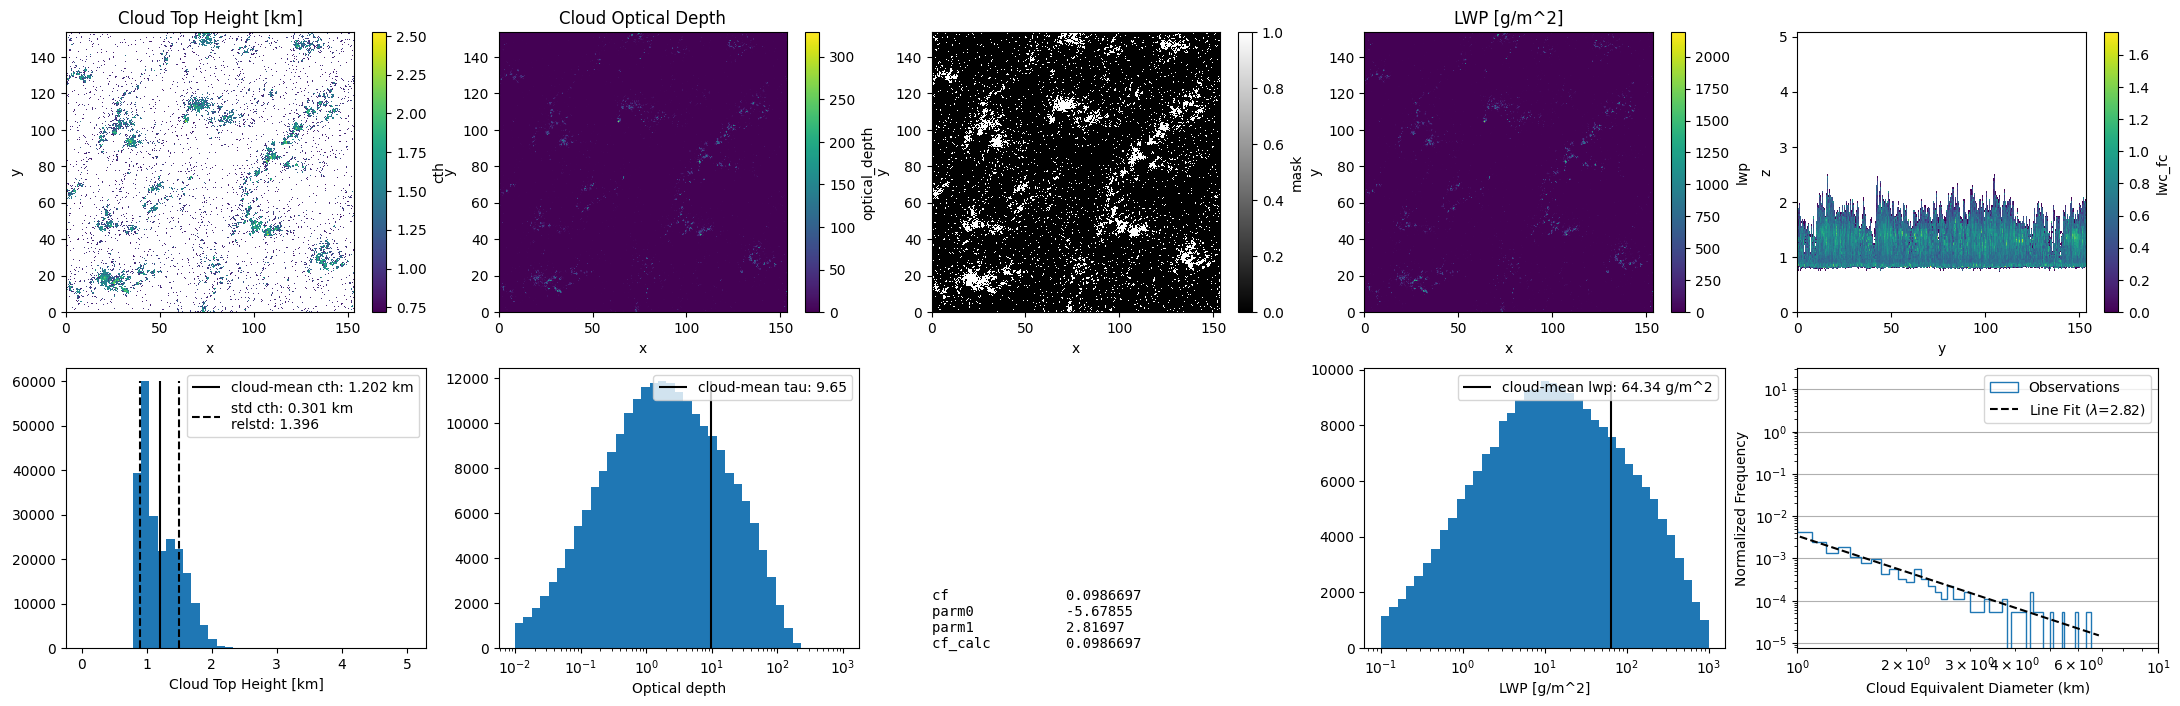

In [36]:
member = 68
time_i = 31
cloud = botany2cloud(ds_3d, member=member, time_i=time_i)
cloud = set_properties(cloud)
outpath = '/data/keeling/a/johntl3/b/Synthetic/cloud_gen/cloud_fields/Botany'
filename = 'member{}_itime{}'.format(member, time_i)
plotCloud(cloud, savebase=outpath, filename=filename)

# Cumulus to Strato Cumulus Transition

/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:48: RuntimeWarning: invalid value encountered in power
  means = (big_z-cbase)**(tau_power - 1.0)
/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:67: RuntimeWarning: Mean of empty slice
  reff = np.sqrt(1e3*np.nanmean(means, axis=(0,1))/(2*np.pi*k*N0))[None,None]*np.ones(ext.shape)
/data/keeling/a/johntl3/miniconda3/envs/synthetic/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


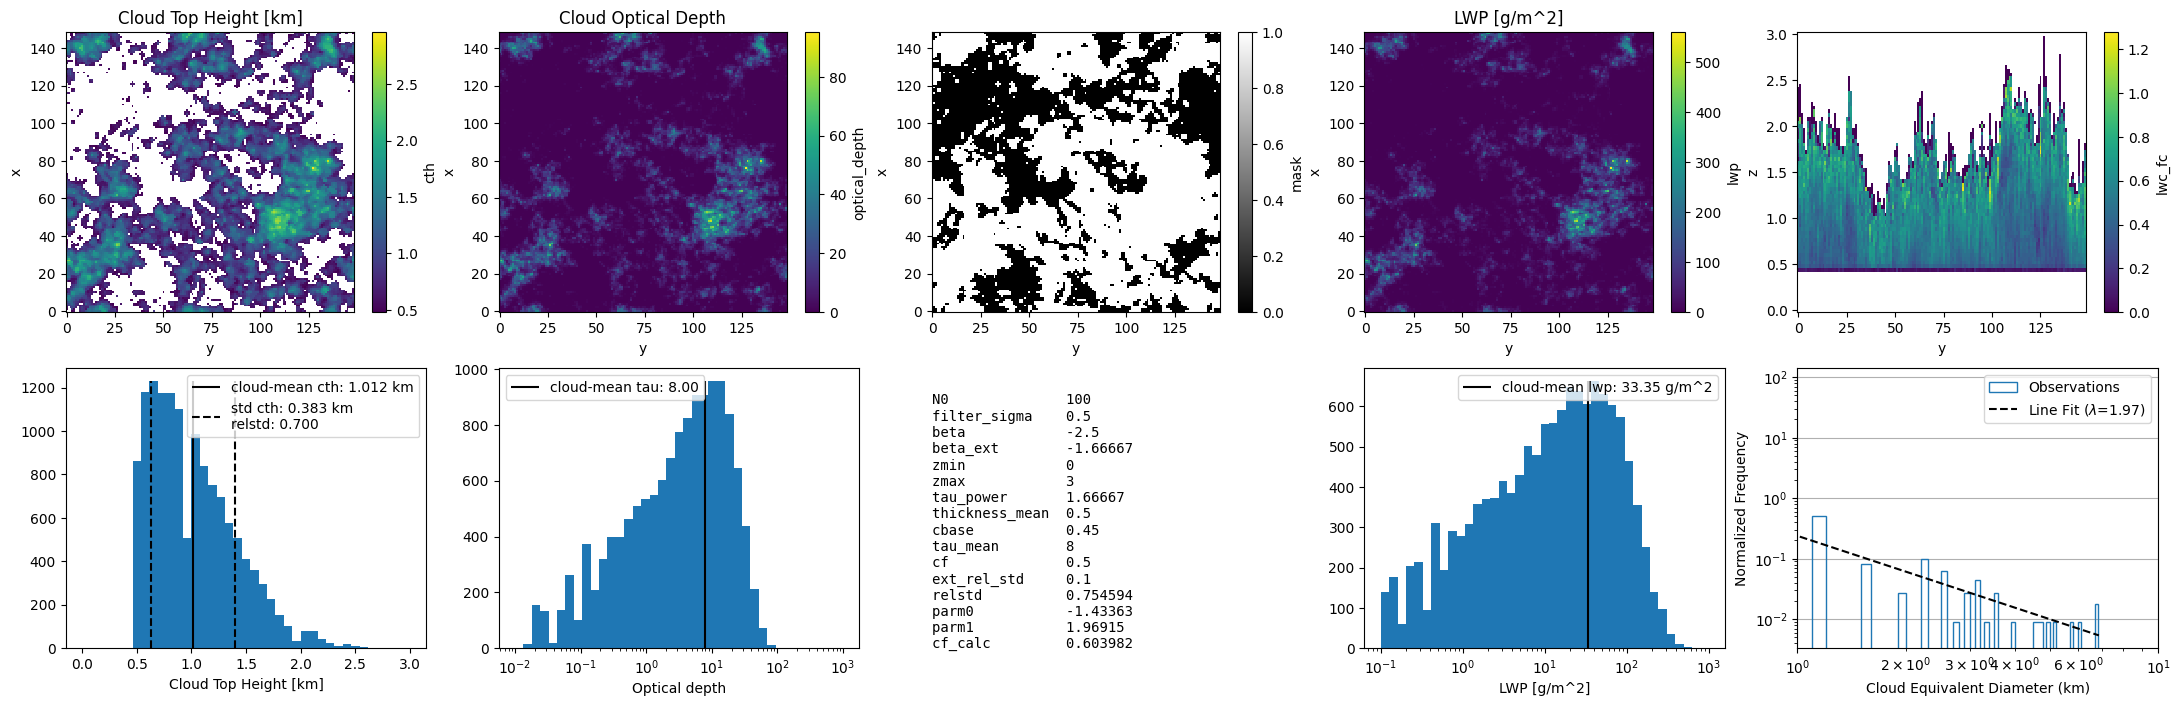

In [10]:
nx = 149
ny = 149
dx = 1.0
dy = 1.0
dz = 0.04
zmin = 0.0
zmax = 3.0
beta = -2.5
beta_ext = -5.0/3.0
cf = 0.5
ext_rel_std = 0.1
tau_mean = 8
relstd = calc_relstd(cf)
thickness_mean = 0.5
tau_power=5.0/3.0
veff = 0.07
N0 = 100.0
cbase=0.45
filter_sigma=0.5
cloud = gc.generate_cloud(nx, ny, dx, dy, dz, zmin, zmax, beta, beta_ext, cf, ext_rel_std,
                        tau_mean, relstd, thickness_mean, tau_power, veff, N0, cbase, filter_sigma)
cloud = set_properties(cloud)

outpath = '/data/keeling/a/johntl3/b/Synthetic/cloud_gen/cloud_fields/Transition'
plotCloud(cloud, savebase=outpath, filename='field')

# StratoCumulus

/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:48: RuntimeWarning: invalid value encountered in power
  means = (big_z-cbase)**(tau_power - 1.0)
/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:67: RuntimeWarning: Mean of empty slice
  reff = np.sqrt(1e3*np.nanmean(means, axis=(0,1))/(2*np.pi*k*N0))[None,None]*np.ones(ext.shape)
/data/keeling/a/johntl3/miniconda3/envs/synthetic/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


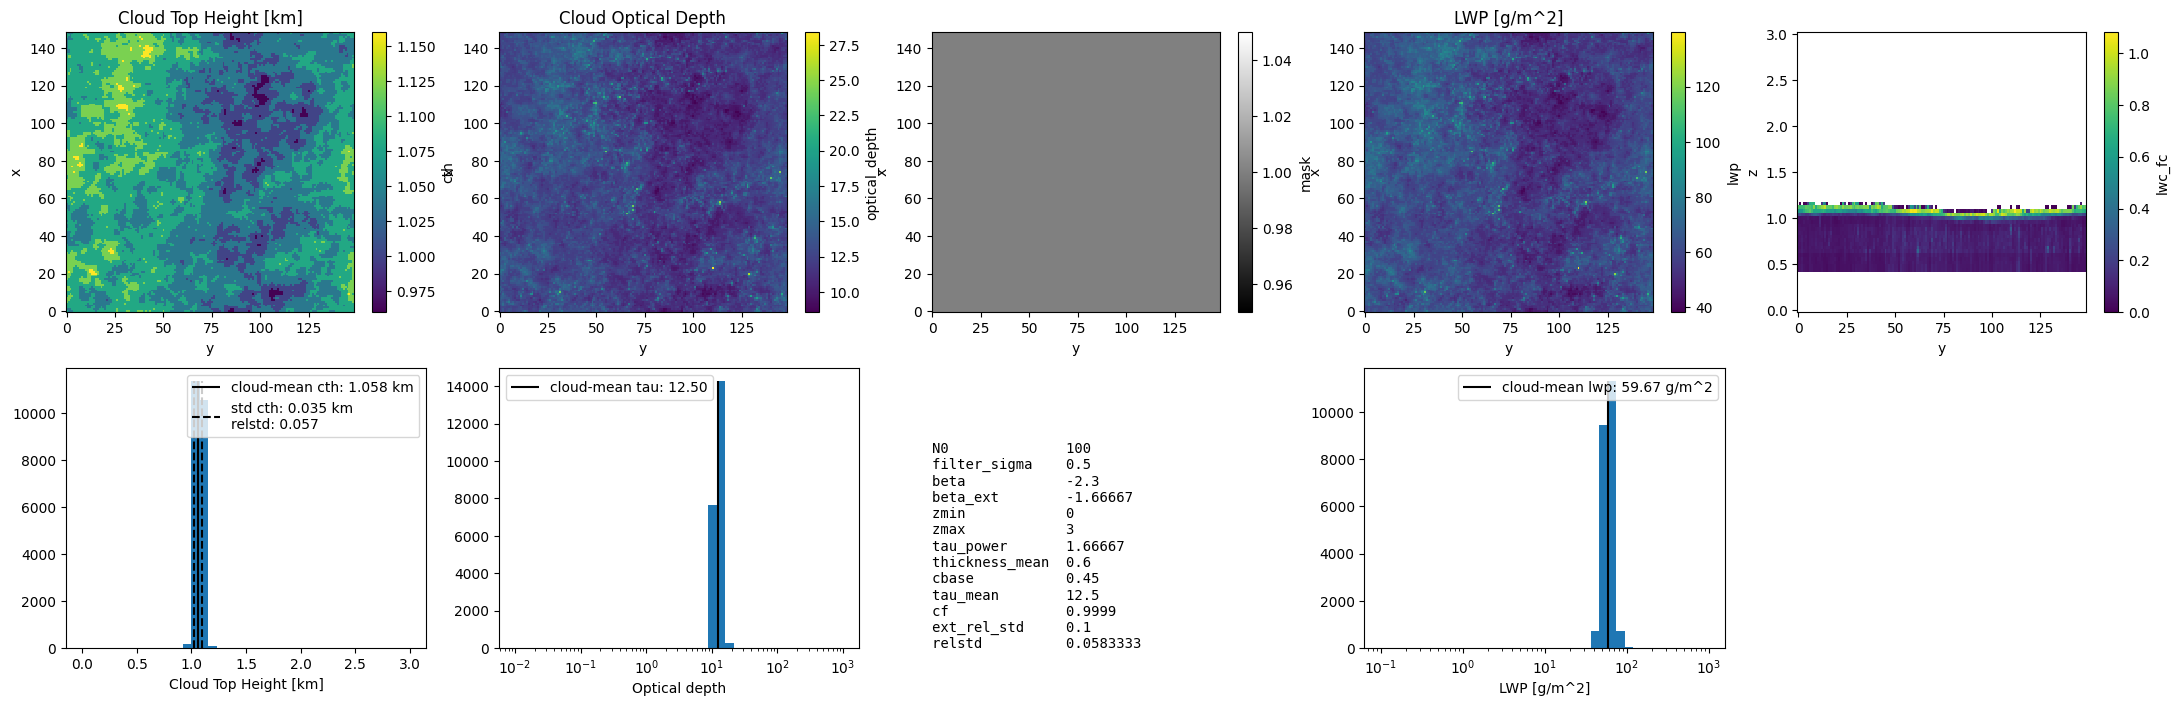

In [13]:
nx = 149
ny = 149
dx = 1.0
dy = 1.0
dz = 0.040
zmin = 0.0
zmax = 3.0
beta = -2.3
beta_ext = -5.0/3.0
cf = 0.9999
ext_rel_std = 0.1
tau_mean = 12.5
thickness_mean = 0.6
relstd = 0.035 / thickness_mean #calc_relstd(cf)
tau_power=5.0/3.0
veff = 0.07
N0 = 100.0
cbase=0.45
filter_sigma=0.5
cloud = gc.generate_cloud(nx, ny, dx, dy, dz, zmin, zmax, beta, beta_ext, cf, ext_rel_std,
                        tau_mean, relstd, thickness_mean, tau_power, veff, N0, cbase, filter_sigma)
cloud = set_properties(cloud)

outpath = '/data/keeling/a/johntl3/b/Synthetic/cloud_gen/cloud_fields/StratoCumulus'
plotCloud(cloud, savebase=outpath, filename='field')

# Picture perfect cloud

In [ ]:
# nx = 50
# ny = 50
# dx = 0.2
# dy = 0.2
# dz = 0.05
# zmin = 0.0
# zmax = 3.0
# beta = -2.6
# beta_ext = -5.0/3.0
# cf = 0.5
# ext_rel_std = 0.1
# tau_mean = 5
# relstd = 0.3
# thickness_mean = 0.75
# tau_power=5.0/3.0
# veff = 0.07
# N0 = 100.0
# cbase=0.45
# filter_sigma=0.5
# cloud = gc.generate_cloud(nx, ny, dx, dy, dz, zmin, zmax, beta, beta_ext, cf, ext_rel_std,
#                         tau_mean, relstd, thickness_mean, tau_power, veff, N0, cbase, filter_sigma)
# tmp = cloud.density.data
# tmp[0,:,:] = tmp[-1,:,:] = tmp[:,0,:] = tmp[:,-1,:] = 0.0
# cloud['density'] = (['x','y','z'], tmp)
# cloud['optical_depth'] = cloud.density.integrate('z')
# cloud['cth'] = cloud.z.where(cloud.density > 0).max('z')
# cloud['mask'] = cloud.cth.notnull()

# f, axs = plt.subplots(2, 3, figsize=(15, 8))
# cloud.cth.plot(ax=axs[0,0])
# axs[0,0].set_title('Cloud Top Height [km]')

# cloud.optical_depth.plot(ax=axs[0,1])
# axs[0,1].set_title('Cloud Optical Depth')

# cloud['mask'].plot(cmap='gray', ax=axs[0,2])

# h = axs[1,0].hist(cloud.cth.data[np.bitwise_not(np.isnan(cloud.cth.data))], bins=np.linspace(zmin, zmax, 40))
# axs[1,0].set_xlabel('Cloud Top Height [km]')

# h = axs[1,1].hist(cloud.optical_depth.data[cloud.optical_depth.data > 0], bins=np.logspace(-2, 3, 40))
# axs[1,1].set_xscale('log')
# axs[1,1].set_xlabel('Optical depth')

# txt = '\n'.join([f'{key:<15s} {value:<n}' for key, value in cloud.attrs.items()])
# axs[1,2].text(0.0, 0.05, txt, fontsize='large', fontfamily='monospace')
# axs[1,2].set_axis_off()

# name = 'ex02'
# savename = '/data/keeling/a/johntl3/b/Synthetic/IO/stochastic/tmp/'
# savename += '{}_sample.png'.format(name)
# f.savefig(savename)
# # plt.close(f)

# densepath = '/data/keeling/a/johntl3/b/Synthetic/IO/stochastic/tmp/'
# densepath += '{}_density.nc'.format(name)
# cloud.to_netcdf(densepath)

/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:48: RuntimeWarning: invalid value encountered in power
  means = (big_z-cbase)**(tau_power - 1.0)
/data/gdi/b/johntl3/Synthetic/cloud_gen/generate_clouds.py:67: RuntimeWarning: Mean of empty slice
  reff = np.sqrt(1e3*np.nanmean(means, axis=(0,1))/(2*np.pi*k*N0))[None,None]*np.ones(ext.shape)
/data/keeling/a/johntl3/miniconda3/envs/synthetic/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


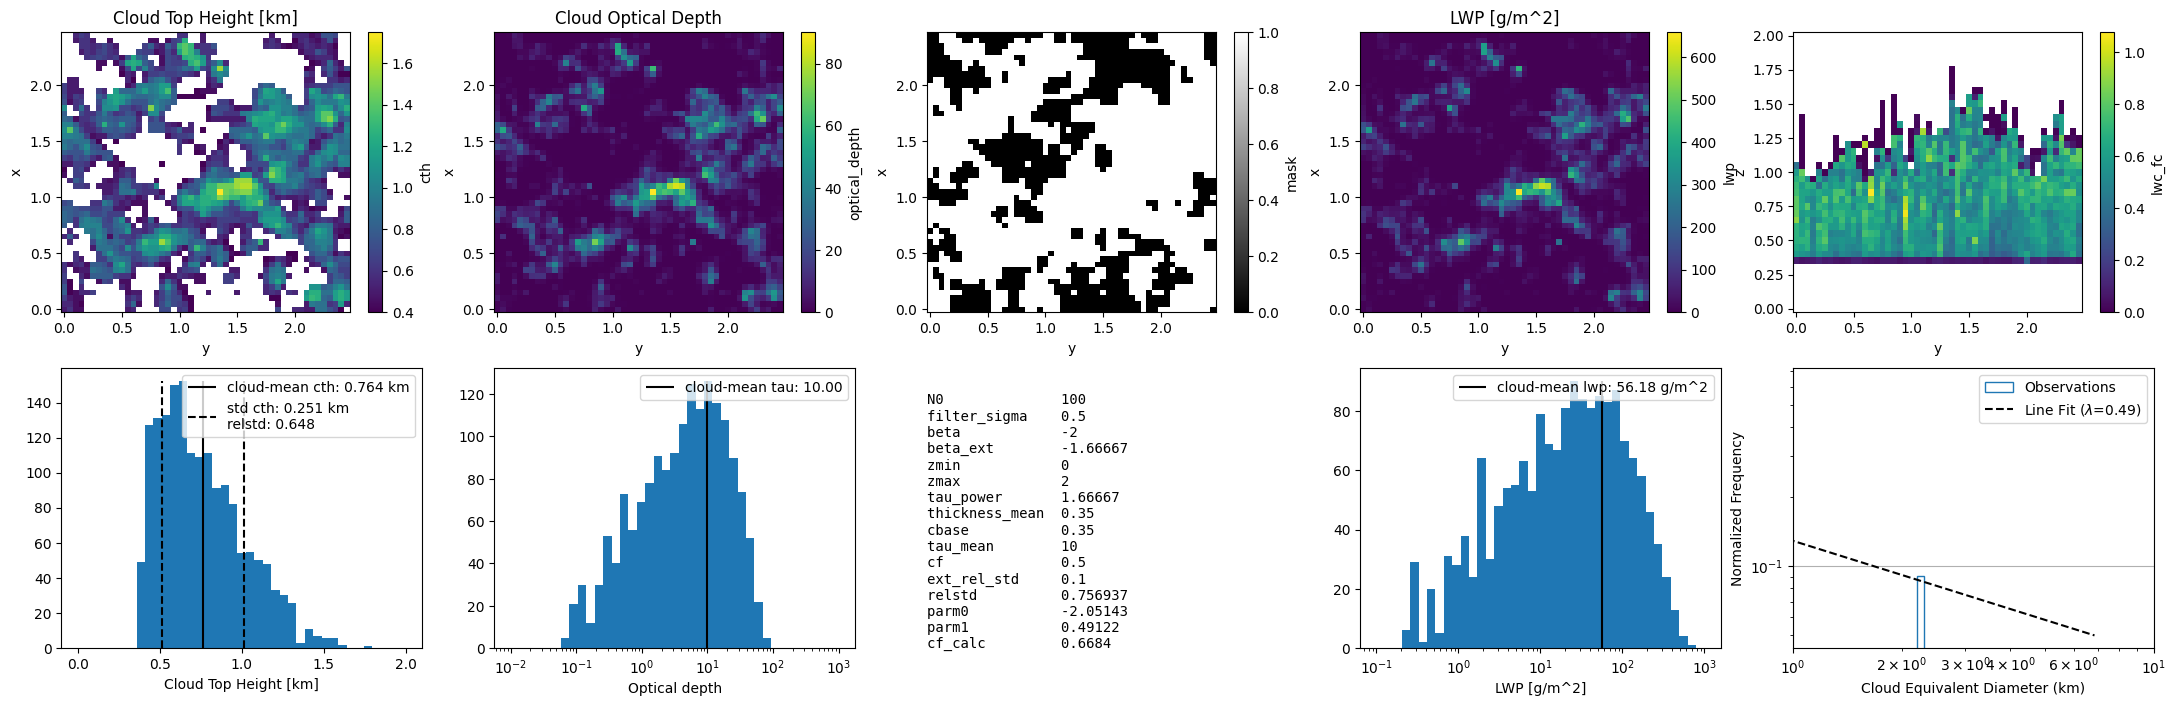

In [15]:
nx = 50
ny = 50
dx = 0.05
dy = 0.05
dz = 0.05
zmin = 0.0
zmax = 2.0
beta = -2
beta_ext = -5.0/3.0
cf = 0.5
ext_rel_std = 0.1
tau_mean = 10
relstd = calc_relstd(cf)
thickness_mean = 0.35
tau_power=5.0/3.0
veff = 0.07
N0 = 100.0
cbase=0.350
filter_sigma=0.5
cloud = gc.generate_cloud(nx, ny, dx, dy, dz, zmin, zmax, beta, beta_ext, cf, ext_rel_std,
                        tau_mean, relstd, thickness_mean, tau_power, veff, N0, cbase, filter_sigma)
cloud = set_properties(cloud)

outpath = '/data/keeling/a/johntl3/b/Synthetic/cloud_gen/cloud_fields/SHDOM_figure'
plotCloud(cloud, savebase=outpath, filename='field')